# Supervised Linear Regression: House Prices (Ames, Iowa)

> Part of [machine-learning-fundamentals](../README.md). Penjelasan di notebook ini ditulis dalam Bahasa Indonesia.

**Fokus:** robustness, analisis multikolinearitas (VIF), dan pencegahan data leakage.
**Reproducibility:** semua proses acak memakai `SEED = 42`.
**Metrik kompetisi Kaggle:** *Mean Absolute Error* (MAE) antara harga prediksi dan harga aktual, dalam USD (halaman *Evaluation* kompetisi *Housing Prices Competition for Kaggle Learn Users*). Model dilatih pada target `log1p(SalePrice)` karena distribusi harga miring; prediksi dikembalikan ke dolar dengan `expm1` sebelum MAE dihitung. Metrik pada skala log (MSE, RMSE, R²) tetap dilaporkan sebagai pelengkap.

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
DATA_DIR = "../data/home-data-for-ml-course/"

## 1. Data Understanding & Preparation
### 1.1 Deskripsi dataset

In [2]:
train_raw = pd.read_csv(DATA_DIR + "train.csv")
test_raw = pd.read_csv(DATA_DIR + "test.csv")
print("Train:", train_raw.shape, "| Test:", test_raw.shape)
print("Jumlah fitur (di luar Id & SalePrice):", train_raw.shape[1] - 2)
print("Fitur numerik:", train_raw.select_dtypes("number").shape[1] - 2, "| kategorikal:", train_raw.select_dtypes("object").shape[1])
train_raw["SalePrice"].describe().round(0)

Train: (1460, 81) | Test: (1459, 80)
Jumlah fitur (di luar Id & SalePrice): 79
Fitur numerik: 36 | kategorikal: 43


count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64

**Deskripsi.** Dataset *House Prices — Advanced Regression Techniques / Housing Prices (home-data-for-ml-course)* berisi data penjualan rumah di Ames, Iowa (sumber: Dean De Cock, Ames Housing Dataset, via Kaggle). Train: **1.460 sampel**, 79 fitur penjelas + `Id` + target **`SalePrice`** (harga jual, USD). Test: 1.459 sampel tanpa target. Metrik Kaggle: **MAE dalam USD**.

### 1.2 Target, missing values, dan outlier

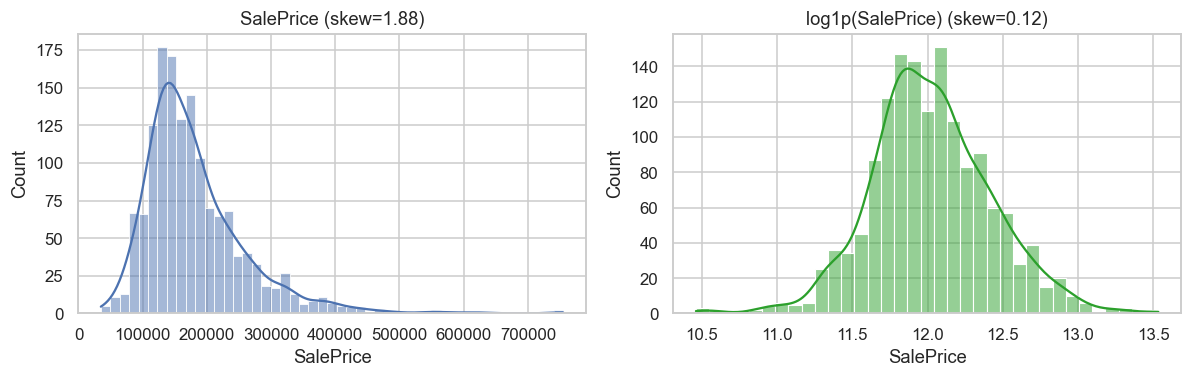

Kolom dengan missing value: 19
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(train_raw["SalePrice"], kde=True, ax=ax[0]); ax[0].set_title(f"SalePrice (skew={train_raw['SalePrice'].skew():.2f})")
sns.histplot(np.log1p(train_raw["SalePrice"]), kde=True, ax=ax[1], color="tab:green"); ax[1].set_title(f"log1p(SalePrice) (skew={np.log1p(train_raw['SalePrice']).skew():.2f})")
plt.tight_layout(); plt.show()

miss = train_raw.isna().sum(); miss = miss[miss > 0].sort_values(ascending=False)
print("Kolom dengan missing value:", len(miss)); print(miss.head(12).to_string())

Target `SalePrice` miring ke kanan (skew > 1), sehingga dimodelkan dalam `log1p`: distribusi menjadi simetris, residual lebih homoskedastik, dan koefisien dapat dibaca sebagai persentase perubahan harga. Sebagian besar missing value pada fitur kategorikal (Alley, PoolQC, Fence, dst.) berarti *fasilitas tidak ada* ("NA" bukan data hilang), sesuai `data_description.txt`. Untuk regresi linear ini kita fokus pada fitur **numerik**; missing value numerik (LotFrontage, MasVnrArea, GarageYrBlt) ditangani dengan imputasi median **di dalam pipeline** (di-fit hanya pada data latih tiap fold → tidak ada leakage).

Outlier GrLivArea>4000 & harga<300rb: [524, 1299]


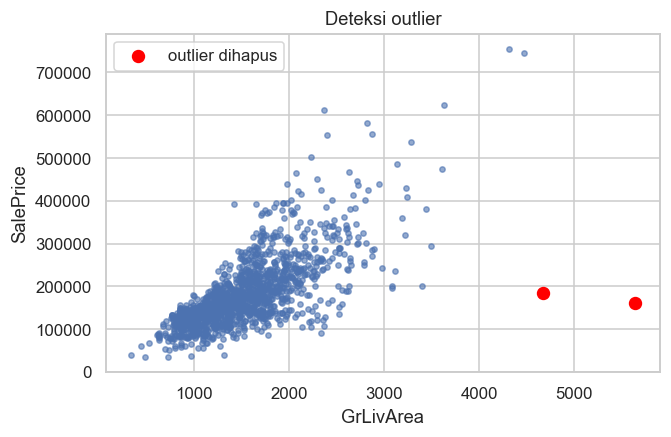

Setelah menghapus outlier: (1458, 81)


In [4]:
# Outlier terkenal pada dataset Ames: rumah sangat luas tetapi murah (De Cock, 2011)
out = train_raw[(train_raw["GrLivArea"] > 4000) & (train_raw["SalePrice"] < 300000)]
print("Outlier GrLivArea>4000 & harga<300rb:", out["Id"].tolist())
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(train_raw["GrLivArea"], train_raw["SalePrice"], s=12, alpha=.6)
ax.scatter(out["GrLivArea"], out["SalePrice"], s=60, c="red", label="outlier dihapus"); ax.legend()
ax.set_xlabel("GrLivArea"); ax.set_ylabel("SalePrice"); ax.set_title("Deteksi outlier"); plt.show()
train = train_raw.drop(index=out.index).reset_index(drop=True)
print("Setelah menghapus outlier:", train.shape)

### 1.3 Pemilihan fitur dan feature engineering ringan
- `Id` → **dibuang** (pengenal baris, bukan prediktor).
- `MSSubClass` → kode kategori (bukan besaran numerik) → dibuang dari set numerik.
- Tahun diubah ke umur: `HouseAge = YrSold − YearBuilt`, `RemodAge = YrSold − YearRemodAdd`; `YearBuilt`, `YearRemodAdd`, `GarageYrBlt` dibuang (redundan/missing).

In [5]:
def make_features(df):
    d = df.copy()
    d["HouseAge"] = d["YrSold"] - d["YearBuilt"]
    d["RemodAge"] = d["YrSold"] - d["YearRemodAdd"]
    drop = ["Id", "MSSubClass", "YearBuilt", "YearRemodAdd", "GarageYrBlt"]
    num = d.select_dtypes("number").drop(columns=[c for c in drop + ["SalePrice"] if c in d.columns])
    return num

X_all = make_features(train)
y_all = np.log1p(train["SalePrice"].values)
print("Fitur numerik awal:", X_all.shape[1])

# Hold-out 80:20 SEBELUM analisis apa pun -> VIF/seleksi fitur hanya melihat data latih
X_tr, X_ho, y_tr, y_ho = train_test_split(X_all, y_all, test_size=0.2, random_state=SEED)
print("Latih:", X_tr.shape, "| Hold-out:", X_ho.shape)

Fitur numerik awal: 34
Latih: (1166, 34) | Hold-out: (292, 34)


### 1.4 Korelasi dan hubungan antar variabel

10 fitur paling berkorelasi dengan log harga:
OverallQual     0.813
GrLivArea       0.731
GarageCars      0.688
GarageArea      0.664
TotalBsmtSF     0.650
1stFlrSF        0.615
HouseAge       -0.591
FullBath        0.584
RemodAge       -0.559
TotRmsAbvGrd    0.543


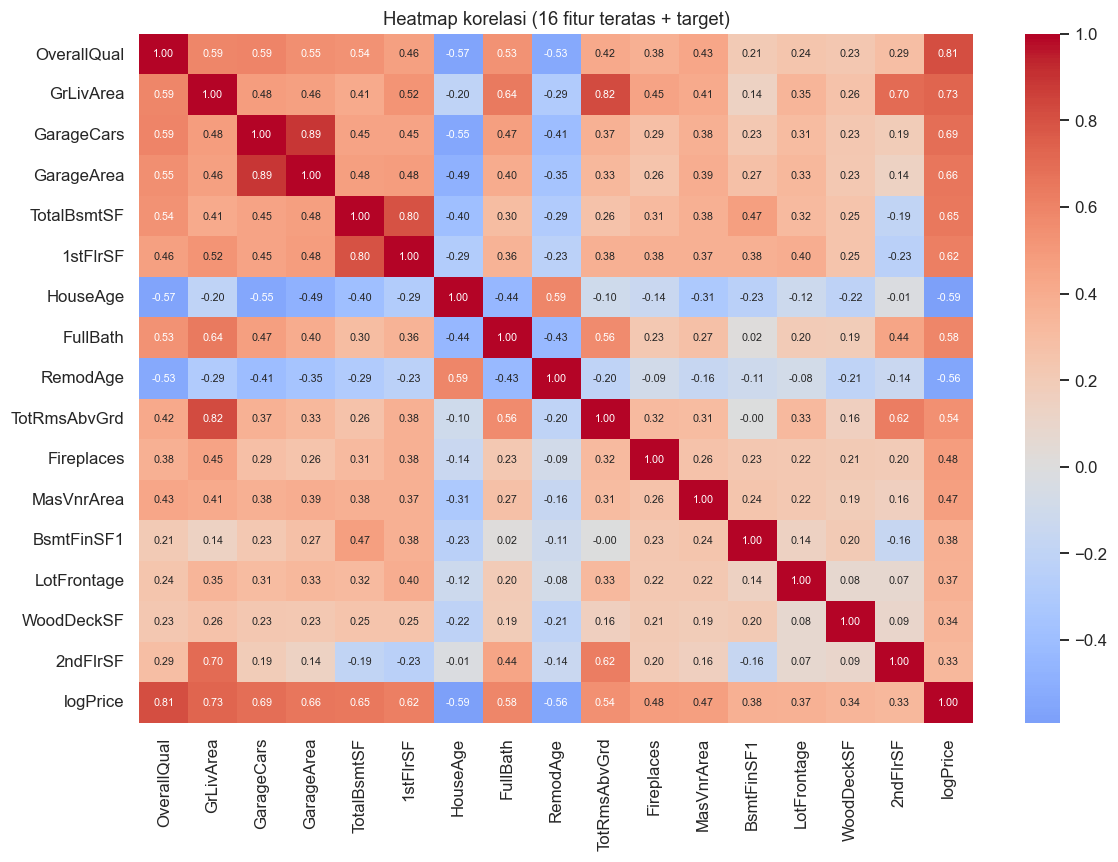

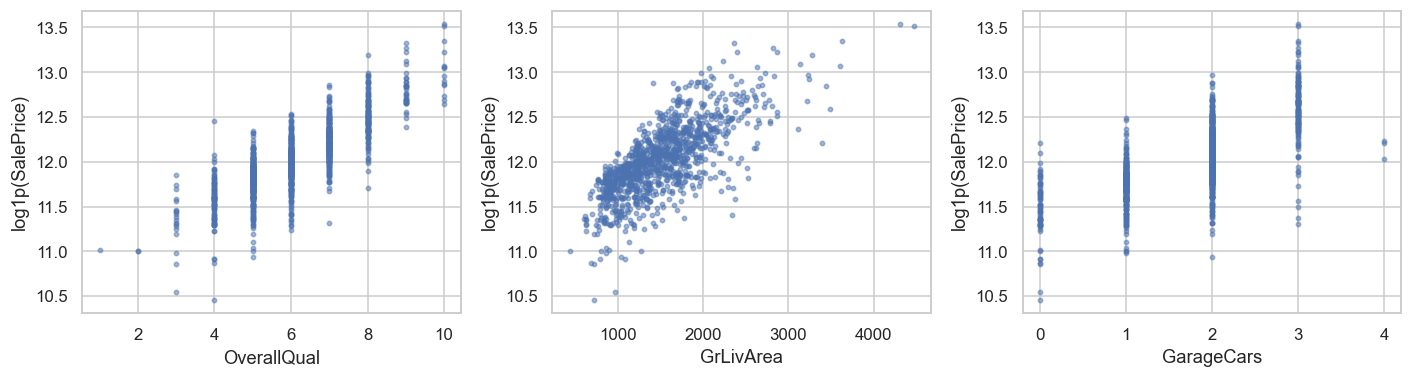

In [6]:
corr_t = X_tr.assign(logPrice=y_tr).corr()["logPrice"].drop("logPrice").sort_values(key=np.abs, ascending=False)
print("10 fitur paling berkorelasi dengan log harga:"); print(corr_t.head(10).round(3).to_string())

fig, ax = plt.subplots(figsize=(11, 8))
top = corr_t.head(16).index.tolist()
sns.heatmap(X_tr[top].assign(logPrice=y_tr).corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7}, ax=ax)
ax.set_title("Heatmap korelasi (16 fitur teratas + target)"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, ["OverallQual", "GrLivArea", "GarageCars"]):
    ax.scatter(X_tr[c], y_tr, s=8, alpha=.5); ax.set_xlabel(c); ax.set_ylabel("log1p(SalePrice)")
plt.tight_layout(); plt.show()

### 1.5 Deteksi Multikolinearitas (VIF)
VIF fitur $j$ = $1/(1-R_j^2)$ dengan $R_j^2$ dari regresi fitur $j$ terhadap semua fitur lain. Dihitung manual (NumPy `lstsq`) pada **data latih saja**, setelah imputasi median dan standarisasi. Aturan: fitur dengan **VIF > 10** dibuang satu per satu (VIF tertinggi dahulu; bila VIF tak hingga/kolinear sempurna, buang yang korelasinya terhadap target paling lemah), lalu VIF dihitung ulang.

In [7]:
def compute_vif(X):
    # VIF tiap kolom. X: DataFrame tanpa NaN.
    Z = (X - X.mean()) / X.std(ddof=0).replace(0, 1)
    A = Z.values
    out = {}
    for j, col in enumerate(Z.columns):
        others = np.delete(A, j, axis=1)
        others = np.c_[np.ones(len(others)), others]
        beta, *_ = np.linalg.lstsq(others, A[:, j], rcond=None)
        resid = A[:, j] - others @ beta
        ss_res, ss_tot = (resid ** 2).sum(), ((A[:, j] - A[:, j].mean()) ** 2).sum()
        r2 = 1 - ss_res / ss_tot if ss_tot > 0 else 0
        out[col] = np.inf if r2 > 1 - 1e-9 else 1 / (1 - r2)
    return pd.Series(out)

imp = SimpleImputer(strategy="median").fit(X_tr)
X_tr_imp = pd.DataFrame(imp.transform(X_tr), columns=X_tr.columns, index=X_tr.index)
vif0 = compute_vif(X_tr_imp).sort_values(ascending=False)
print("VIF awal (10 tertinggi):"); print(vif0.head(10).round(2).to_string())
print("Jumlah fitur VIF>10:", int((vif0 > 10).sum()))

VIF awal (10 tertinggi):
BsmtFinSF1       inf
BsmtFinSF2       inf
BsmtUnfSF        inf
TotalBsmtSF      inf
1stFlrSF         inf
2ndFlrSF         inf
LowQualFinSF     inf
GrLivArea        inf
GarageCars      5.76
GarageArea      5.31
Jumlah fitur VIF>10: 8


In [8]:
abs_corr = X_tr_imp.apply(lambda c: abs(np.corrcoef(c, y_tr)[0, 1])).fillna(0)
keep, log_drop = list(X_tr_imp.columns), []
while True:
    v = compute_vif(X_tr_imp[keep])
    if v.max() <= 10: break
    cand = v[np.isinf(v)].index.tolist() if np.isinf(v).any() else [v.idxmax()]
    drop = min(cand, key=lambda c: abs_corr[c])
    log_drop.append((drop, float(v[drop]), float(abs_corr[drop])))
    keep.remove(drop)

print("Fitur dibuang akibat VIF > 10 (urutan):")
for n, vv, cc in log_drop: print(f"  {n:<14} VIF={vv:>10.2f}  |corr target|={cc:.3f}")
vif_final = compute_vif(X_tr_imp[keep]).sort_values(ascending=False)
print(f"\nFitur tersisa: {len(keep)} | VIF maksimum sekarang: {vif_final.max():.2f}")
print(vif_final.head(6).round(2).to_string())

Fitur dibuang akibat VIF > 10 (urutan):
  BsmtFinSF2     VIF=       inf  |corr target|=0.001
  LowQualFinSF   VIF=       inf  |corr target|=0.033
  GrLivArea      VIF=    132.79  |corr target|=0.731
  TotalBsmtSF    VIF=     10.62  |corr target|=0.650

Fitur tersisa: 30 | VIF maksimum sekarang: 5.74
GarageCars      5.74
2ndFlrSF        5.44
GarageArea      5.31
1stFlrSF        4.97
TotRmsAbvGrd    4.79
HouseAge        3.93


**Penjelasan.** Kolinearitas sempurna muncul karena fitur turunan, mis. `TotalBsmtSF = BsmtFinSF1 + BsmtFinSF2 + BsmtUnfSF` dan `GrLivArea = 1stFlrSF + 2ndFlrSF + LowQualFinSF`. Kolinearitas membuat matriks $X^\top X$ hampir singular → koefisien OLS tidak stabil (varians besar, tanda bisa terbalik) dan sulit ditafsirkan, walaupun akurasi prediksi tidak banyak berubah. Karena itu kita buang yang VIF > 10, mempertahankan yang paling informatif bagi target.

**Hasil:** 4 fitur dibuang — `BsmtFinSF2`, `LowQualFinSF` (bagian dari kolinearitas sempurna, korelasi target hampir nol), lalu `GrLivArea` (VIF 132,8) dan `TotalBsmtSF` (VIF 10,6). Walaupun `GrLivArea` adalah fitur dengan korelasi kedua tertinggi (0,73), **informasinya tidak hilang**: `GrLivArea` ≈ `1stFlrSF + 2ndFlrSF`, dan keduanya tetap ada di model. Begitu juga `TotalBsmtSF` = `BsmtFinSF1 + BsmtUnfSF (+ BsmtFinSF2)`. Setelah itu VIF maksimum turun menjadi 5,74 (`GarageCars`), sehingga 30 fitur tersisa bebas dari multikolinearitas berat.

### 1.6 Deteksi Data Leakage
Pemeriksaan dan temuan:
1. **`Id`** — pengenal baris tanpa makna prediktif; dibuang (pola Id dapat bocor jika data terurut menurut waktu).
2. **Fitur yang hanya diketahui setelah target?** `YrSold`, `MoSold`, `SaleType`, `SaleCondition` diketahui pada saat transaksi (bukan hasil dari harga), sehingga tidak dianggap leakage; `YrSold` hanya dipakai untuk menghitung umur rumah. Tidak ada kolom turunan langsung dari `SalePrice`.
3. **Leakage prosedural (paling sering terjadi):** imputasi median, standarisasi, VIF, dan seleksi fitur seluruhnya di-fit **hanya pada data latih** (VIF dihitung setelah split 80:20; imputer & scaler berada di dalam `Pipeline`, sehingga di-fit ulang pada tiap fold K-Fold). Hold-out 20% tidak pernah ikut menentukan fitur maupun hiperparameter.

In [9]:
FEATURES = keep.copy()
print(len(FEATURES), "fitur akhir:", FEATURES)

30 fitur akhir: ['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'MasVnrArea', 'BsmtFinSF1', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'HouseAge', 'RemodAge']


## 2. Model Development
### 2.1 Pendekatan (a): From scratch (NumPy)
Fitur distandarisasi dengan statistik data latih. **Normal Equation:** $\hat\beta = (X^\top X)^{-1}X^\top y$ (dengan kolom bias). **Gradient Descent:** $\beta \leftarrow \beta - \alpha\,\frac{2}{N}X^\top(X\beta - y)$. Simple Linear Regression memakai satu fitur (`OverallQual`), Multiple memakai semua `FEATURES`.

In [10]:
class ScratchLinearRegression(BaseEstimator, RegressorMixin):
    # OLS dari nol dengan NumPy. method: 'normal' atau 'gd'.
    def __init__(self, method="normal", lr=0.05, n_iter=3000):
        self.method, self.lr, self.n_iter = method, lr, n_iter
    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        Xb = np.c_[np.ones(len(X)), X]
        if self.method == "normal":
            self.beta_ = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y          # (X'X)^-1 X'y
        else:
            beta = np.zeros(Xb.shape[1]); self.loss_ = []
            for _ in range(self.n_iter):
                resid = Xb @ beta - y
                beta -= self.lr * (2 / len(y)) * (Xb.T @ resid)
                self.loss_.append(np.mean(resid ** 2))
            self.beta_ = beta
        self.intercept_, self.coef_ = self.beta_[0], self.beta_[1:]
        return self
    def predict(self, X):
        return np.c_[np.ones(len(X)), np.asarray(X, float)] @ self.beta_

def pre(): return [("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]

# --- Simple Linear Regression: OverallQual -> log harga
Xs_tr, Xs_ho = X_tr[["OverallQual"]], X_ho[["OverallQual"]]
simple_sc = make_pipeline(*[s for _, s in pre()], ScratchLinearRegression("normal")).fit(Xs_tr, y_tr)
simple_sk = make_pipeline(*[s for _, s in pre()], LinearRegression()).fit(Xs_tr, y_tr)
print("Simple LR  scratch  (intercept, coef):", simple_sc[-1].intercept_.round(5), simple_sc[-1].coef_.round(5))
print("Simple LR  sklearn  (intercept, coef):", round(simple_sk[-1].intercept_, 5), simple_sk[-1].coef_.round(5))
print("R2 hold-out simple: scratch=%.4f sklearn=%.4f" % (r2_score(y_ho, simple_sc.predict(Xs_ho)), r2_score(y_ho, simple_sk.predict(Xs_ho))))

Simple LR  scratch  (intercept, coef): 12.02336 [0.32277]
Simple LR  sklearn  (intercept, coef): 12.02336 [0.32277]
R2 hold-out simple: scratch=0.7217 sklearn=0.7217


In [11]:
# --- Multiple Linear Regression
XF_tr, XF_ho = X_tr[FEATURES], X_ho[FEATURES]
m_normal = make_pipeline(*[s for _, s in pre()], ScratchLinearRegression("normal")).fit(XF_tr, y_tr)
m_gd = make_pipeline(*[s for _, s in pre()], ScratchLinearRegression("gd")).fit(XF_tr, y_tr)
m_sk = make_pipeline(*[s for _, s in pre()], LinearRegression()).fit(XF_tr, y_tr)

def metrics(y, p):
    mse = mean_squared_error(y, p)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

comp = pd.DataFrame({"Scratch Normal Eq": metrics(y_ho, m_normal.predict(XF_ho)),
                     "Scratch Grad Desc": metrics(y_ho, m_gd.predict(XF_ho)),
                     "Sklearn LinearRegression": metrics(y_ho, m_sk.predict(XF_ho))}).T
display(comp.round(5))
print("Selisih maks koefisien Normal-Eq vs sklearn:", np.abs(m_normal[-1].coef_ - m_sk[-1].coef_).max())
print("Selisih maks koefisien GD vs sklearn       :", np.abs(m_gd[-1].coef_ - m_sk[-1].coef_).max())

,MSE,RMSE,MAE,R2
Scratch Normal Eq,0.01797,0.13404,0.09586,0.89342
Scratch Grad Desc,0.01797,0.13404,0.09586,0.89342
Sklearn LinearRegression,0.01797,0.13404,0.09586,0.89342


Selisih maks koefisien Normal-Eq vs sklearn: 4.760081218080359e-15
Selisih maks koefisien GD vs sklearn       : 3.915756607852927e-13


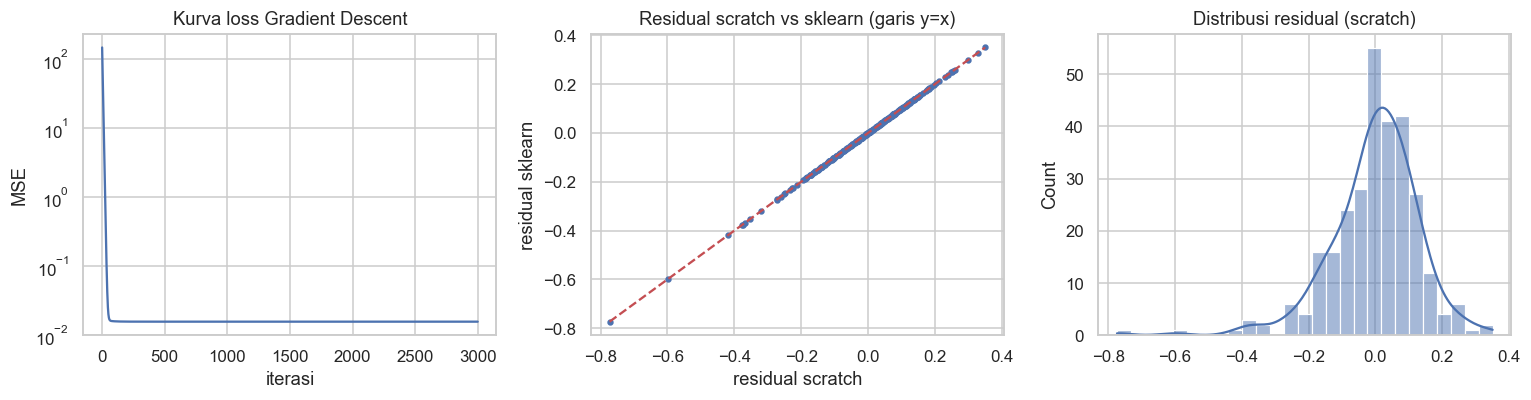

In [12]:
res_n = y_ho - m_normal.predict(XF_ho); res_s = y_ho - m_sk.predict(XF_ho)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(m_gd[-1].loss_); ax[0].set_yscale("log"); ax[0].set_title("Kurva loss Gradient Descent"); ax[0].set_xlabel("iterasi"); ax[0].set_ylabel("MSE")
ax[1].scatter(res_n, res_s, s=10); ax[1].set_title("Residual scratch vs sklearn (garis y=x)"); ax[1].set_xlabel("residual scratch"); ax[1].set_ylabel("residual sklearn")
lim = [min(res_n.min(), res_s.min()), max(res_n.max(), res_s.max())]; ax[1].plot(lim, lim, "r--")
sns.histplot(res_n, kde=True, ax=ax[2]); ax[2].set_title("Distribusi residual (scratch)")
plt.tight_layout(); plt.show()

**Perbandingan.** Normal Equation dan `LinearRegression` sklearn menghasilkan koefisien yang sama (selisih ≈ nol → implementasi benar); Gradient Descent konvergen ke solusi yang sama bila iterasi cukup. Residual ketiganya identik secara praktis dan mendekati distribusi normal berpusat di 0.

### 2.2 Regularisasi: Ridge dan Lasso
$\lambda$ (`alpha`) dipilih dengan GridSearchCV 5-fold **pada data latih saja** (scoring: RMSE negatif).

In [13]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
def pipe(est): return Pipeline(pre() + [("m", est)])

grid_r = GridSearchCV(pipe(Ridge(random_state=SEED)), {"m__alpha": np.logspace(-2, 3, 30)}, cv=kf, scoring="neg_root_mean_squared_error").fit(XF_tr, y_tr)
grid_l = GridSearchCV(pipe(Lasso(random_state=SEED, max_iter=50000)), {"m__alpha": np.logspace(-5, -0.5, 30)}, cv=kf, scoring="neg_root_mean_squared_error").fit(XF_tr, y_tr)
ols = pipe(LinearRegression()).fit(XF_tr, y_tr)
ridge, lasso = grid_r.best_estimator_, grid_l.best_estimator_
print("Ridge alpha terbaik:", round(grid_r.best_params_["m__alpha"], 4), "| Lasso alpha terbaik:", round(grid_l.best_params_["m__alpha"], 6))

coefs = pd.DataFrame({"OLS": ols[-1].coef_, "Ridge": ridge[-1].coef_, "Lasso": lasso[-1].coef_}, index=FEATURES)
print("Fitur yang di-nol-kan Lasso:", coefs.index[coefs["Lasso"] == 0].tolist())
display(coefs.reindex(coefs["OLS"].abs().sort_values(ascending=False).index).round(4))

Ridge alpha terbaik: 8.5317 | Lasso alpha terbaik: 0.003039
Fitur yang di-nol-kan Lasso: ['MasVnrArea', 'BsmtHalfBath', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']


,OLS,Ridge,Lasso
1stFlrSF,0.1051,0.1012,0.1065
2ndFlrSF,0.0988,0.0934,0.0911
OverallQual,0.0943,0.0946,0.1046
HouseAge,-0.0884,-0.0851,-0.0781
BsmtFinSF1,0.0623,0.0618,0.0537
OverallCond,0.0539,0.0525,0.0455
BsmtUnfSF,0.0354,0.0350,0.0230
TotRmsAbvGrd,0.0275,0.0291,0.0186
GarageCars,0.0243,0.0244,0.0245
GarageArea,0.0233,0.0242,0.0262


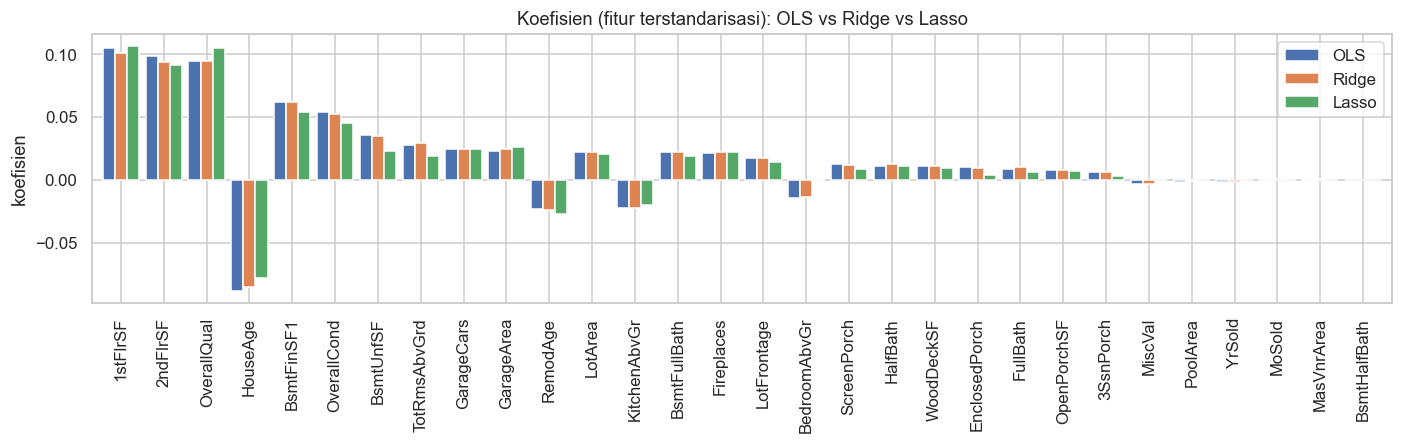

Norma L2 koefisien -> OLS: 0.2259 | Ridge: 0.2208 | Lasso: 0.2163


In [14]:
order = coefs["OLS"].abs().sort_values(ascending=False).index
ax = coefs.loc[order].plot(kind="bar", figsize=(13, 4.2), width=.85)
ax.set_title("Koefisien (fitur terstandarisasi): OLS vs Ridge vs Lasso"); ax.set_ylabel("koefisien"); plt.tight_layout(); plt.show()
print("Norma L2 koefisien -> OLS: %.4f | Ridge: %.4f | Lasso: %.4f" % tuple(np.linalg.norm(coefs[c]) for c in ["OLS","Ridge","Lasso"]))

**Interpretasi regularisasi.** Ridge menyusutkan semua koefisien secara halus (penalti L2) tetapi tidak ada yang tepat nol; Lasso (penalti L1) menyusutkan beberapa koefisien menjadi **tepat nol** (daftar di atas). Fitur yang di-nol-kan Lasso adalah fitur yang kontribusi marginalnya kecil/terduplikasi informasinya oleh fitur lain (korelasi dengan target lemah atau sudah dijelaskan fitur kuat seperti `OverallQual` dan `GrLivArea`) — Lasso bertindak sebagai seleksi fitur otomatis.

## 3. Model Evaluation
### 3.1 K-Fold Cross-Validation (K = 5) pada data latih
Metrik: MSE, RMSE, MAE, R² pada skala log, ditambah **MAE dalam USD (metrik Kaggle)** pada sel berikutnya. Pipeline memastikan imputer/scaler di-fit ulang pada tiap fold.

In [15]:
scoring = {"MSE": "neg_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}
models = {"OLS (sklearn)": ols, "OLS (scratch Normal Eq)": make_pipeline(*[s for _, s in pre()], ScratchLinearRegression("normal")),
          "Ridge": ridge, "Lasso": lasso}
rows = []
for name, m in models.items():
    cv = cross_validate(m, XF_tr, y_tr, cv=kf, scoring=scoring)
    mse, mae, r2 = -cv["test_MSE"], -cv["test_MAE"], cv["test_R2"]
    rmse = np.sqrt(mse)
    rows.append({"Model": name, "MSE": f"{mse.mean():.5f} ± {mse.std():.5f}", "RMSE": f"{rmse.mean():.4f} ± {rmse.std():.4f}",
                 "MAE": f"{mae.mean():.4f} ± {mae.std():.4f}", "R2": f"{r2.mean():.4f} ± {r2.std():.4f}"})
cv_table = pd.DataFrame(rows).set_index("Model"); display(cv_table)

,MSE,RMSE,MAE,R2
Model,,,,
OLS (sklearn),0.01707 ± 0.00269,0.1303 ± 0.0104,0.0912 ± 0.0058,0.8909 ± 0.0110
OLS (scratch Normal Eq),0.01707 ± 0.00269,0.1303 ± 0.0104,0.0912 ± 0.0058,0.8909 ± 0.0110
Ridge,0.01707 ± 0.00277,0.1302 ± 0.0107,0.0914 ± 0.0061,0.8909 ± 0.0114
Lasso,0.01674 ± 0.00242,0.1290 ± 0.0095,0.0909 ± 0.0059,0.8928 ± 0.0110


In [16]:
# Metrik kompetisi Kaggle: MAE dalam USD (prediksi log dikembalikan ke dolar dengan expm1)
from sklearn.base import clone
rows = []
for name, m in models.items():
    maes = []
    for tr_i, va_i in kf.split(XF_tr):
        mm = clone(m).fit(XF_tr.iloc[tr_i], y_tr[tr_i])
        maes.append(mean_absolute_error(np.expm1(y_tr[va_i]), np.expm1(mm.predict(XF_tr.iloc[va_i]))))
    maes = np.array(maes)
    rows.append({"Model": name, "CV MAE USD (mean)": round(maes.mean()), "CV MAE USD (std)": round(maes.std())})
mae_usd_table = pd.DataFrame(rows).set_index("Model"); display(mae_usd_table)

,CV MAE USD (mean),CV MAE USD (std)
Model,,
OLS (sklearn),15905,1354
OLS (scratch Normal Eq),15905,1354
Ridge,15956,1407
Lasso,15908,1420


### 3.2 Hold-out 80:20 sebagai pembanding

In [17]:
rows = []
for name, m in models.items():
    m.fit(XF_tr, y_tr); rows.append({"Model": name, **metrics(y_ho, m.predict(XF_ho))})
ho_table = pd.DataFrame(rows).set_index("Model"); display(ho_table.round(5))

,MSE,RMSE,MAE,R2
Model,,,,
OLS (sklearn),0.01797,0.13404,0.09586,0.89342
OLS (scratch Normal Eq),0.01797,0.13404,0.09586,0.89342
Ridge,0.01804,0.13430,0.09600,0.89300
Lasso,0.01810,0.13455,0.09643,0.89261


**Mengapa K-Fold lebih robust.** Hold-out hanya memberi **satu** estimasi yang sangat bergantung pada pembagian acak tertentu (varians tinggi; bisa untung/sial) dan hanya memakai 80% data untuk melatih serta 20% untuk menguji. K-Fold menguji pada seluruh data bergantian sebanyak K kali, sehingga memberi *mean ± std* dan memperlihatkan stabilitas model. Perbedaan angka K-Fold vs hold-out di atas menunjukkan besarnya variasi akibat pembagian data.

### 3.3 Residual Plot dan Predicted vs Actual (hold-out, model Ridge)

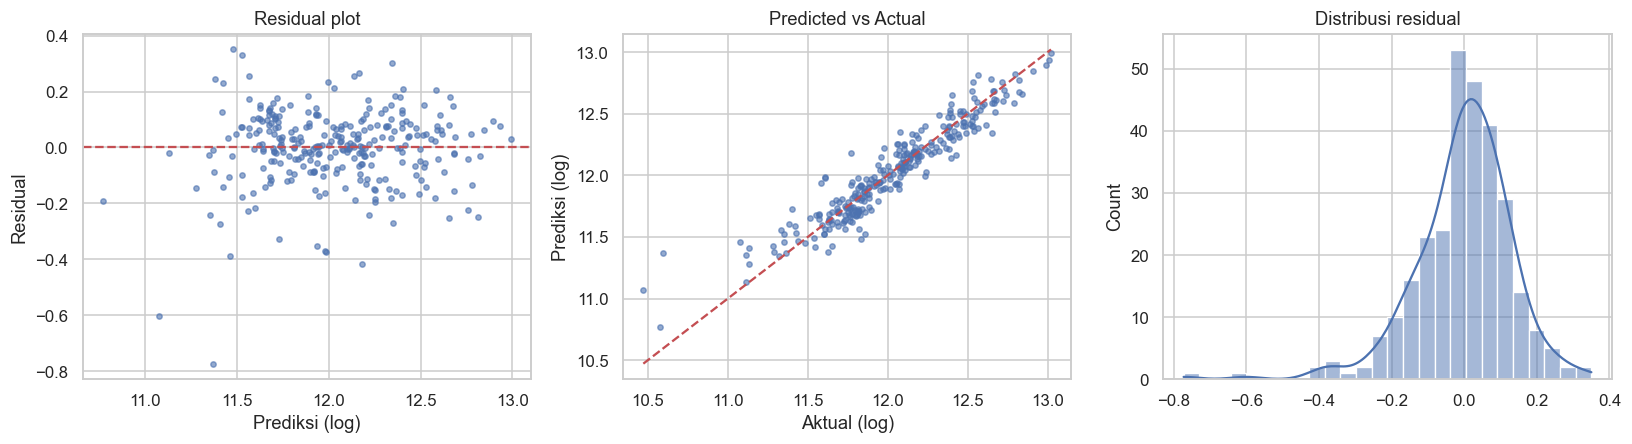

Rata-rata residual: -0.0026 | std residual: 0.1343


In [18]:
best = ridge.fit(XF_tr, y_tr); pred = best.predict(XF_ho); resid = y_ho - pred
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].scatter(pred, resid, s=12, alpha=.6); ax[0].axhline(0, c="r", ls="--"); ax[0].set_xlabel("Prediksi (log)"); ax[0].set_ylabel("Residual"); ax[0].set_title("Residual plot")
ax[1].scatter(y_ho, pred, s=12, alpha=.6); lim = [y_ho.min(), y_ho.max()]; ax[1].plot(lim, lim, "r--"); ax[1].set_xlabel("Aktual (log)"); ax[1].set_ylabel("Prediksi (log)"); ax[1].set_title("Predicted vs Actual")
sns.histplot(resid, kde=True, ax=ax[2]); ax[2].set_title("Distribusi residual")
plt.tight_layout(); plt.show()
print("Rata-rata residual: %.4f | std residual: %.4f" % (resid.mean(), resid.std()))

## 4. Interpretasi dan Insight
### 4.1 Makna koefisien dan fitur paling berpengaruh
Fitur distandarisasi, jadi koefisien = perubahan **log harga** per kenaikan 1 simpangan baku fitur (ceteris paribus). Perubahan persentase harga ≈ $e^{\beta}-1$.

,koef (Ridge),perubahan harga per +1 SD (%)
1stFlrSF,0.101,10.646
OverallQual,0.095,9.925
2ndFlrSF,0.093,9.787
HouseAge,-0.085,-8.156
BsmtFinSF1,0.062,6.370
OverallCond,0.053,5.391
BsmtUnfSF,0.035,3.560
TotRmsAbvGrd,0.029,2.953
GarageCars,0.024,2.473
RemodAge,-0.024,-2.396


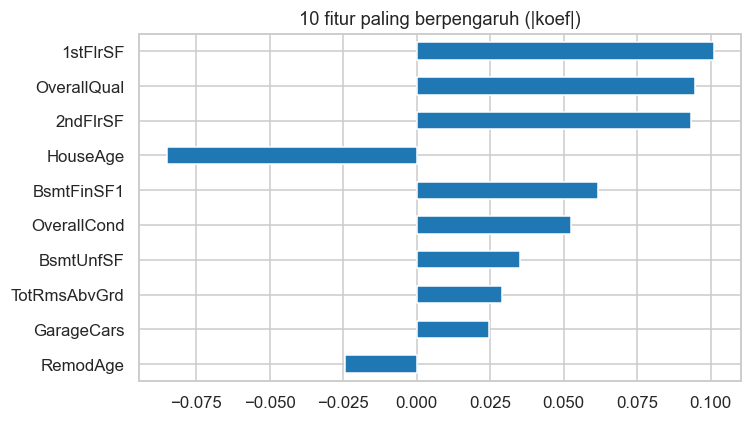

In [19]:
c = pd.Series(ridge[-1].coef_, index=FEATURES)
imp_tbl = pd.DataFrame({"koef (Ridge)": c, "perubahan harga per +1 SD (%)": (np.exp(c) - 1) * 100}).reindex(c.abs().sort_values(ascending=False).index)
display(imp_tbl.head(10).round(3))
ax = imp_tbl["koef (Ridge)"].head(10)[::-1].plot(kind="barh", figsize=(7, 4), color="tab:blue"); ax.set_title("10 fitur paling berpengaruh (|koef|)"); plt.tight_layout(); plt.show()

### 4.2 Seberapa baik model? (kuantitatif & intuitif) dan Business Impact

In [20]:
price_true = np.expm1(y_ho); price_pred = np.expm1(pred)
err = price_pred - price_true
mae_usd, med_ape = np.mean(np.abs(err)), np.median(np.abs(err) / price_true) * 100
rmse_log = np.sqrt(mean_squared_error(y_ho, pred))
print(f"RMSE log hold-out                 : {rmse_log:.4f}")
print(f"R2 (skala log)                    : {r2_score(y_ho, pred):.4f}")
print(f"MAE dalam USD                     : ${mae_usd:,.0f}  | median APE: {med_ape:.1f}% | harga rata-rata: ${price_true.mean():,.0f}")
n_tx = 1000
print(f"\nBusiness impact (asumsi {n_tx} transaksi):")
print(f"  Total selisih absolut rata-rata  : ${mae_usd*n_tx:,.0f}")
print(f"  Bias rata-rata (prediksi-aktual) : ${err.mean():,.0f}/rumah -> total ${err.mean()*n_tx:,.0f}")
print(f"  Overvalue (prediksi > aktual)     : {np.mean(err>0)*100:.0f}% kasus, rata-rata +${err[err>0].mean():,.0f}")
print(f"  Undervalue (prediksi < aktual)    : {np.mean(err<0)*100:.0f}% kasus, rata-rata -${abs(err[err<0].mean()):,.0f}")

RMSE log hold-out                 : 0.1343
R2 (skala log)                    : 0.8930
MAE dalam USD                     : $16,525  | median APE: 7.3% | harga rata-rata: $181,369

Business impact (asumsi 1000 transaksi):
  Total selisih absolut rata-rata  : $16,524,814
  Bias rata-rata (prediksi-aktual) : $-1,223/rumah -> total $-1,222,822
  Overvalue (prediksi > aktual)     : 47% kasus, rata-rata +$16,307
  Undervalue (prediksi < aktual)    : 53% kasus, rata-rata -$16,717


**Penilaian model & kesimpulan.**

- **Metrik Kaggle (MAE USD):** lihat tabel CV MAE USD di bagian 3.1; skor Kaggle hasil submission adalah **MAE $15.747**, konsisten dengan MAE hold-out $16.525 (model final dilatih pada data yang lebih banyak).
- **Kuantitatif:** K-Fold 5-fold memberi RMSE log **0,130 ± 0,011** dan R² **0,891 ± 0,011** (Lasso sedikit terbaik: 0,129 / 0,893). Hold-out: RMSE log 0,134, R² 0,893. Model menjelaskan sekitar 89% variasi log harga. Dalam dolar: MAE **$16.525** per rumah dengan median kesalahan relatif **7,3%** dari harga (harga rata-rata $181.369).
- **Intuitif:** penentu harga terkuat adalah luas lantai 1 dan 2 (`1stFlrSF`, `2ndFlrSF`; +1 SD ≈ +10% harga), kualitas keseluruhan `OverallQual` (+1 SD ≈ +9,9%), dan umur rumah `HouseAge` (+1 SD lebih tua ≈ −8,2%). Ini sesuai intuisi pasar properti: rumah yang lebih luas, lebih berkualitas, dan lebih baru lebih mahal. `BedroomAbvGr` dan `KitchenAbvGr` bertanda negatif karena *ceteris paribus*: dengan luas sama, lebih banyak kamar berarti kamar lebih sempit.
- **Residual:** rata-rata residual −0,003 (hampir tidak bias), tersebar acak di sekitar nol tanpa pola corong yang jelas, jadi asumsi linearitas dan homoskedastisitas pada skala log cukup terpenuhi.
- **Business impact:** dengan MAE $16.525, pada **1.000 transaksi** total selisih absolut sekitar **$16,5 juta**. Kesalahannya hampir seimbang: 47% kasus overvalue (rata-rata +$16.307, risiko pembeli/bank membayar terlalu mahal) dan 53% undervalue (rata-rata −$16.717, risiko penjual kehilangan nilai). Bias bersih hanya −$1.223/rumah, jadi secara portofolio kesalahan banyak saling menutup, tetapi tiap transaksi individual tetap berisiko sekitar 7-9% dari harga.
- **Apakah cukup baik?** Untuk *screening* dan estimasi awal harga: ya. Untuk keputusan bernilai tinggi (appraisal kredit, penetapan harga final): belum. Model hanya memakai fitur numerik dan hubungan linear, sehingga tidak menangkap lokasi (`Neighborhood`) dan fitur kualitas kategorikal.
- **Rekomendasi:** (1) tambahkan fitur kategorikal (Neighborhood, ExterQual, KitchenQual) dengan encoding; (2) coba model non-linear atau ensembel; (3) sediakan interval prediksi agar risiko over/undervaluation terukur per transaksi; (4) latih ulang secara berkala untuk mengikuti perubahan pasar.

## 5. Bonus
### 5.1 Polynomial Regression (degree 2 dan 3) vs Linear
Untuk menghindari ledakan fitur, polinomial dibuat dari 6 fitur terkuat saja (digabung dengan fitur linear lain), dan diregularisasi Ridge.

In [21]:
from sklearn.compose import ColumnTransformer
top6 = list(abs_corr[FEATURES].sort_values(ascending=False).head(6).index)
rest = [f for f in FEATURES if f not in top6]
# SimpleImputer menghasilkan array -> pakai indeks kolom untuk ColumnTransformer
idx = {f: i for i, f in enumerate(FEATURES)}
def poly_model(deg):
    ct = ColumnTransformer([("poly", Pipeline([("sc", StandardScaler()), ("pf", PolynomialFeatures(deg, include_bias=False)), ("sc2", StandardScaler())]), [idx[f] for f in top6]),
                            ("lin", StandardScaler(), [idx[f] for f in rest])])
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("ct", ct), ("m", Ridge(alpha=10.0, random_state=SEED))])

rows = []
for name, m in {"Linear (Ridge)": ridge, "Poly degree 2": poly_model(2), "Poly degree 3": poly_model(3)}.items():
    cv = cross_validate(m, XF_tr, y_tr, cv=kf, scoring={"MSE": "neg_mean_squared_error", "R2": "r2"})
    rm = np.sqrt(-cv["test_MSE"]); m.fit(XF_tr, y_tr)
    rows.append({"Model": name, "CV RMSE (mean ± std)": f"{rm.mean():.4f} ± {rm.std():.4f}", "CV R2": f"{cv['test_R2'].mean():.4f}", "Hold-out RMSE": round(np.sqrt(mean_squared_error(y_ho, m.predict(XF_ho))), 4)})
display(pd.DataFrame(rows).set_index("Model"))

,CV RMSE (mean ± std),CV R2,Hold-out RMSE
Model,,,
Linear (Ridge),0.1302 ± 0.0107,0.8909,0.1343
Poly degree 2,0.1292 ± 0.0117,0.8925,0.1317
Poly degree 3,0.1340 ± 0.0139,0.8844,0.1277


**Hasil:** degree 2 sedikit lebih baik dari linear (CV RMSE 0,1292 vs 0,1302) karena dapat menangkap efek kuadratik dan interaksi antar fitur terkuat. Degree 3 justru **lebih buruk** di CV (0,1340) dan paling tidak stabil (std 0,0139), walaupun hold-out-nya kebetulan terbaik (0,1277). Ini contoh nyata mengapa K-Fold lebih dapat dipercaya: satu hold-out bisa memberi kesan menyesatkan. Degree 3 cenderung *overfitting*, sehingga degree 2 adalah kompromi terbaik, tetapi peningkatannya kecil dibanding tambahan kompleksitas.

### 5.2 Prediksi untuk Kaggle (`submission_housing.csv`)
Model akhir dilatih ulang pada **seluruh** data latih (setelah outlier dibuang). File telah diunggah ke Kaggle dengan skor **MAE = 15.747,45** (USD).

Test set memuat rumah ekstrem (luas jauh di atas data latih), sehingga model linear mengekstrapolasi harga yang tidak realistis (di atas $1,8 juta). Prediksi di-*clip* ke rentang harga data latih, karena model tidak punya dasar untuk memprediksi di luar rentang yang pernah dilihat.

In [22]:
final = Pipeline(pre() + [("m", Ridge(alpha=grid_r.best_params_["m__alpha"], random_state=SEED))]).fit(X_all[FEATURES], y_all)
X_test = make_features(test_raw)[FEATURES]
raw_pred = np.expm1(final.predict(X_test))
lo, hi = train["SalePrice"].min(), train["SalePrice"].max()
print(f"Prediksi di luar rentang latih [${lo:,} - ${hi:,}]: {int(((raw_pred < lo) | (raw_pred > hi)).sum())} rumah (maks mentah ${raw_pred.max():,.0f})")
sub = pd.DataFrame({"Id": test_raw["Id"], "SalePrice": np.clip(raw_pred, lo, hi)})
sub.to_csv("submission_housing.csv", index=False)
print(sub.shape, "| rentang harga prediksi: $%d - $%d" % (sub.SalePrice.min(), sub.SalePrice.max()))
sub.head()

Prediksi di luar rentang latih [$34,900 - $755,000]: 1 rumah (maks mentah $1,823,195)
(1459, 2) | rentang harga prediksi: $55796 - $755000


,Id,SalePrice
0,1461,121627.420885
1,1462,144121.326857
2,1463,172903.738636
3,1464,196585.397364
4,1465,183474.183462


## 6. Referensi

| No | Sumber / Tool | Tujuan Penggunaan | Link / Keterangan |
|----|---------------|-------------------|-------------------|
| 1 | Kaggle — Housing Prices (home-data-for-ml-course) | Sumber dataset | https://www.kaggle.com/competitions/home-data-for-ml-course |
| 2 | De Cock (2011), Ames Housing Dataset | Dokumentasi dataset & saran penghapusan outlier | Journal of Statistics Education 19(3) |
| 3 | Scikit-Learn documentation | Pipeline, KFold, Ridge/Lasso, GridSearchCV | https://scikit-learn.org |